In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = "../Task1_Data_Cleaning/output/amazon_products_sales_data_cleaned_final.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 41713
Columns: 17


In [2]:
# STEP 2 - CHECK DATASET COLUMNS

print("Column Names:")
for i, col in enumerate(df.columns, 1):
    print(i, ":", col)

Column Names:
1 : product_title
2 : product_rating
3 : total_reviews
4 : purchased_last_month
5 : discounted_price
6 : Price_on_variant
7 : original_price
8 : is_best_seller
9 : is_sponsored
10 : has_coupon
11 : buy_box_availability
12 : delivery_details
13 : sustainability_tags
14 : product_image_url
15 : product_url
16 : data_collected_at
17 : discount_percentage


In [3]:
# STEP 3 - BASIC DATASET INFORMATION

print("=" * 60)
print("STEP 3 - BASIC DATASET INFORMATION")
print("=" * 60)

print("\nDataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

STEP 3 - BASIC DATASET INFORMATION

Dataset Shape:
(41713, 17)

Data Types:
product_title               str
product_rating          float64
total_reviews           float64
purchased_last_month    float64
discounted_price        float64
Price_on_variant            str
original_price          float64
is_best_seller              str
is_sponsored                str
has_coupon                  str
buy_box_availability        str
delivery_details            str
sustainability_tags         str
product_image_url           str
product_url                 str
data_collected_at           str
discount_percentage     float64
dtype: object

Missing Values:
product_title           0
product_rating          0
total_reviews           0
purchased_last_month    0
discounted_price        0
Price_on_variant        0
original_price          0
is_best_seller          0
is_sponsored            0
has_coupon              0
buy_box_availability    0
delivery_details        0
sustainability_tags     0
product_ima

C:\Users\abc\AppData\Local\Temp\ipykernel_1636\216780230.py:17: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


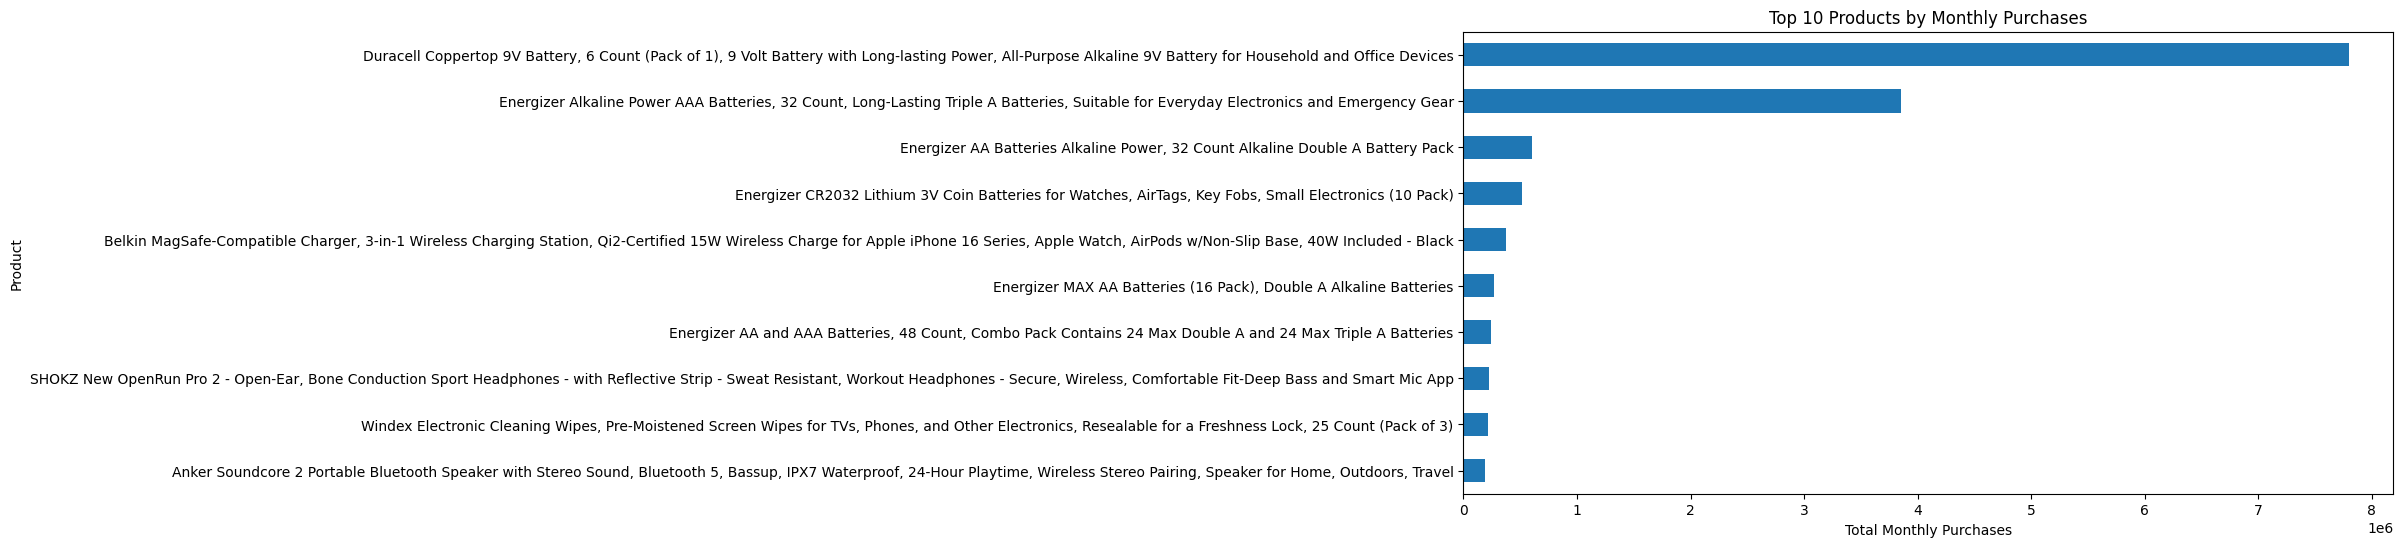

In [4]:
# STEP 4 - BAR CHART
# Top 10 Products by Monthly Purchases

top_products = (
    df.groupby("product_title")["purchased_last_month"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Monthly Purchases")
plt.xlabel("Total Monthly Purchases")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

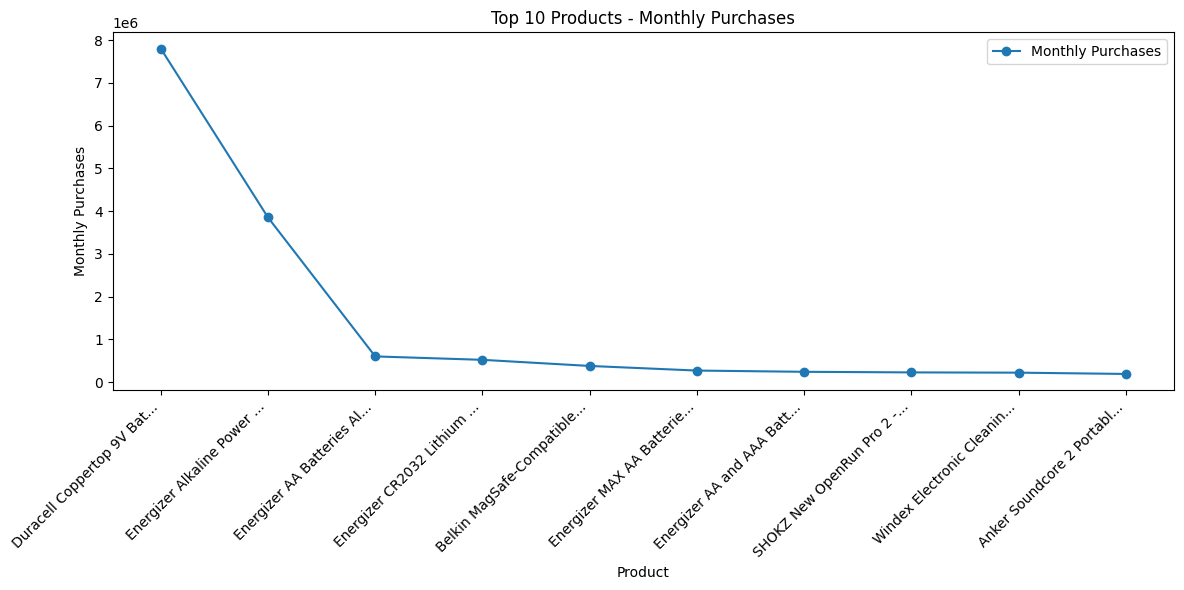

In [5]:
# STEP 5 - LINE CHART
# Top 10 Products by Monthly Purchases

plt.figure(figsize=(12, 6))

top_products.sort_values(ascending=False).plot(
    kind="line",
    marker="o"
)

plt.title("Top 10 Products - Monthly Purchases")
plt.xlabel("Product")
plt.ylabel("Monthly Purchases")
plt.xticks(
    range(len(top_products)),
    [str(x)[:25] + "..." for x in top_products.index],
    rotation=45,
    ha="right"
)
plt.legend(["Monthly Purchases"])
plt.tight_layout()
plt.show()

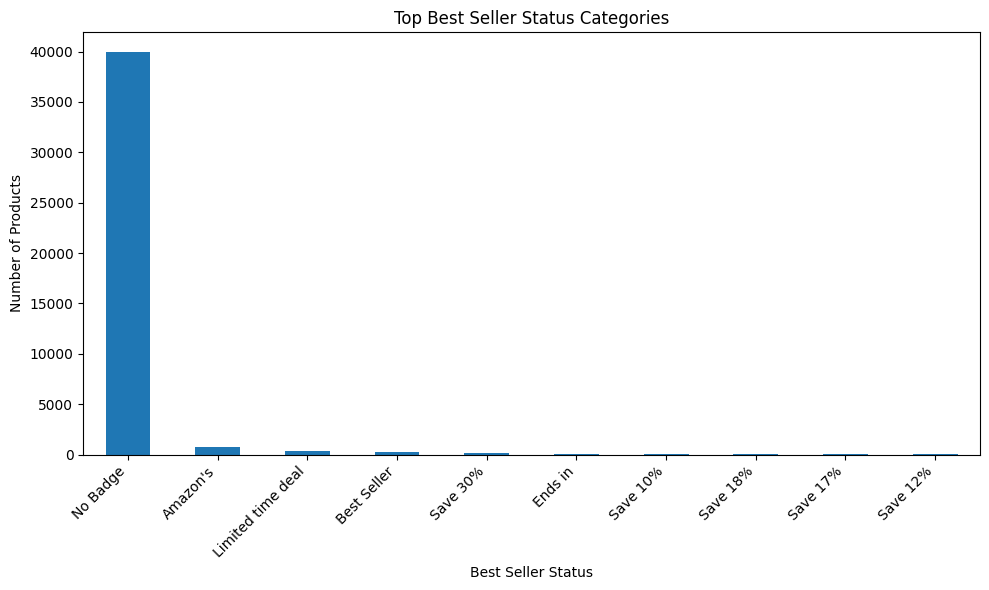

In [7]:
# STEP 6 - BEST SELLER STATUS DISTRIBUTION

status_counts = df["is_best_seller"].value_counts().head(10)

plt.figure(figsize=(10, 6))
status_counts.plot(kind="bar")

plt.title("Top Best Seller Status Categories")
plt.xlabel("Best Seller Status")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

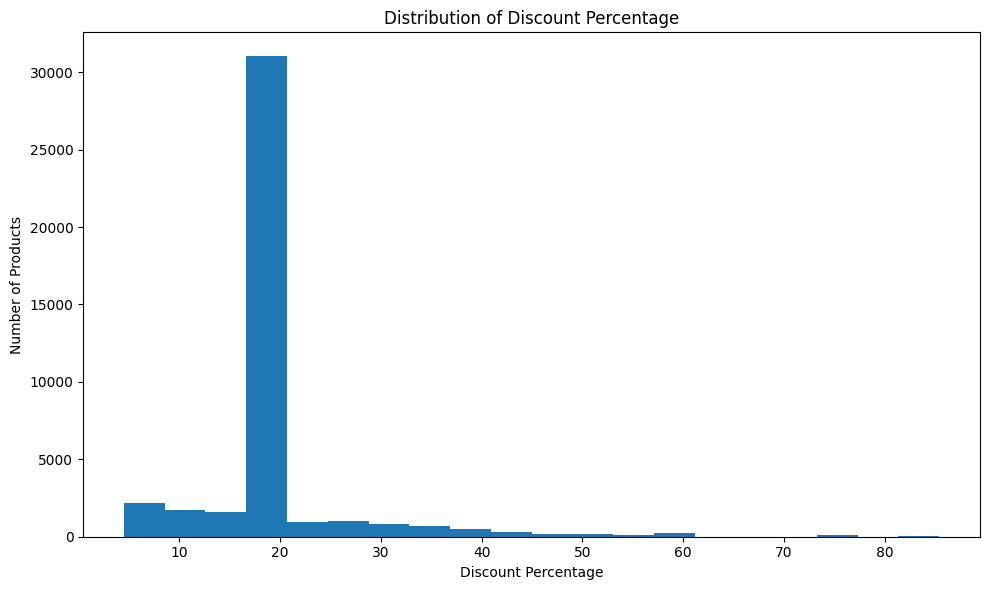

In [8]:
# STEP 6 - DISCOUNT DISTRIBUTION

plt.figure(figsize=(10, 6))

plt.hist(df["discount_percentage"], bins=20)

plt.title("Distribution of Discount Percentage")
plt.xlabel("Discount Percentage")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

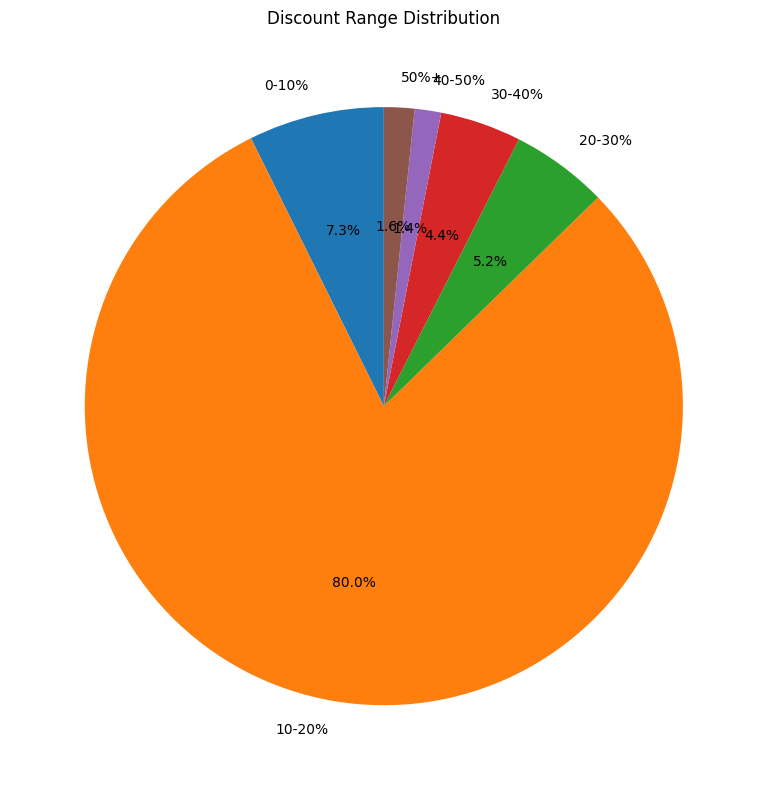

In [10]:
# STEP 7 - PIE CHART: DISCOUNT RANGE DISTRIBUTION

discount_bins = [0, 10, 20, 30, 40, 50, 100]
discount_labels = [
    "0-10%",
    "10-20%",
    "20-30%",
    "30-40%",
    "40-50%",
    "50%+"
]

df["discount_range"] = pd.cut(
    df["discount_percentage"],
    bins=discount_bins,
    labels=discount_labels,
    include_lowest=True
)

discount_counts = df["discount_range"].value_counts().sort_index()

plt.figure(figsize=(8, 8))

plt.pie(
    discount_counts.values,
    labels=discount_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Discount Range Distribution")
plt.tight_layout()
plt.show()

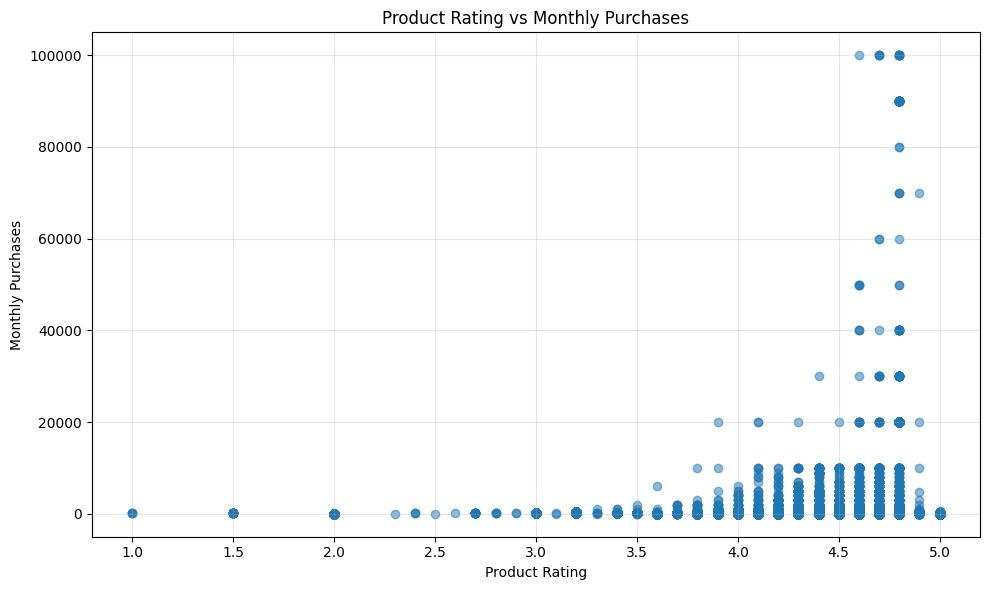

In [11]:
# STEP 8 - SCATTER PLOT
# Product Rating vs Monthly Purchases

plt.figure(figsize=(10, 6))

plt.scatter(
    df['product_rating'],
    df['purchased_last_month'],
    alpha=0.5
)

plt.title("Product Rating vs Monthly Purchases")
plt.xlabel("Product Rating")
plt.ylabel("Monthly Purchases")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# STEP 9 - KEY INSIGHTS FROM VISUALIZATIONS

print("=" * 70)
print("TASK 3 - KEY INSIGHTS")
print("=" * 70)

# 1. Top product by monthly purchases
top_product = df.loc[
    df['purchased_last_month'].idxmax(),
    'product_title'
]
top_purchases = df['purchased_last_month'].max()

print("\n1. TOP PRODUCT")
print("Product:", top_product)
print("Monthly Purchases:", f"{top_purchases:,.0f}")

# 2. Average product rating
avg_rating = df['product_rating'].mean()

print("\n2. PRODUCT RATINGS")
print("Average Product Rating:", round(avg_rating, 2))

# 3. Average discount
avg_discount = df['discount_percentage'].mean()

print("\n3. DISCOUNT ANALYSIS")
print("Average Discount Percentage:", round(avg_discount, 2), "%")

# 4. Highest discount
max_discount = df['discount_percentage'].max()

print("\n4. HIGHEST DISCOUNT")
print("Highest Discount:", round(max_discount, 2), "%")

# 5. Best Seller status
best_seller_counts = df['is_best_seller'].value_counts()

print("\n5. BEST SELLER STATUS")
print(best_seller_counts)

# 6. Overall conclusion
print("\n6. OVERALL CONCLUSION")
print("• Most products have ratings concentrated around 4 to 5.")
print("• Discount percentages are mainly concentrated around the 20% range.")
print("• A small number of products have exceptionally high monthly purchases.")
print("• The scatter plot shows that higher ratings do not always guarantee higher purchases.")
print("• Most products do not have a Best Seller badge.")

TASK 3 - KEY INSIGHTS

1. TOP PRODUCT
Product: Texas Instruments TI-84 Plus CE Color Graphing Calculator, Black
Monthly Purchases: 100,000

2. PRODUCT RATINGS
Average Product Rating: 4.39

3. DISCOUNT ANALYSIS
Average Discount Percentage: 19.21 %

4. HIGHEST DISCOUNT
Highest Discount: 85.42 %

5. BEST SELLER STATUS
is_best_seller
No Badge             39912
Amazon's               733
Limited time deal      360
Best Seller            275
Save 30%               125
Ends in                 97
Save 10%                61
Save 18%                57
Save 17%                51
Save 12%                26
Save 9%                 14
Save 77%                 2
Name: count, dtype: int64

6. OVERALL CONCLUSION
• Most products have ratings concentrated around 4 to 5.
• Discount percentages are mainly concentrated around the 20% range.
• A small number of products have exceptionally high monthly purchases.
• The scatter plot shows that higher ratings do not always guarantee higher purchases.
• Most pro

In [13]:
# STEP 10 - TASK 3 FINAL SUMMARY

print("=" * 70)
print("TASK 3 - DATA VISUALIZATION DASHBOARD")
print("FINAL SUMMARY")
print("=" * 70)

print("\nVisualizations Completed:")
print("1. Bar Chart - Top 10 Products by Monthly Purchases")
print("2. Line Chart - Top 10 Products by Monthly Purchases")
print("3. Pie Chart - Best Seller Status Distribution")
print("4. Pie Chart - Discount Range Distribution")
print("5. Histogram - Discount Percentage Distribution")
print("6. Scatter Plot - Product Rating vs Monthly Purchases")

print("\nKey Findings:")
print("• The highest monthly purchases observed are 100,000.")
print("• The average product rating is 4.39.")
print("• The average discount percentage is 19.21%.")
print("• The maximum discount percentage is 85.42%.")
print("• Most products do not have a Best Seller badge.")

print("\nTask 3 Status: COMPLETED")
print("=" * 70)

TASK 3 - DATA VISUALIZATION DASHBOARD
FINAL SUMMARY

Visualizations Completed:
1. Bar Chart - Top 10 Products by Monthly Purchases
2. Line Chart - Top 10 Products by Monthly Purchases
3. Pie Chart - Best Seller Status Distribution
4. Pie Chart - Discount Range Distribution
5. Histogram - Discount Percentage Distribution
6. Scatter Plot - Product Rating vs Monthly Purchases

Key Findings:
• The highest monthly purchases observed are 100,000.
• The average product rating is 4.39.
• The average discount percentage is 19.21%.
• The maximum discount percentage is 85.42%.
• Most products do not have a Best Seller badge.

Task 3 Status: COMPLETED


In [14]:
# ============================================================
# TASK 3 - FINAL SUMMARY
# ============================================================

print("=" * 70)
print("TASK 3 - DATA VISUALIZATION DASHBOARD")
print("FINAL SUMMARY")
print("=" * 70)

print("\nVisualizations Completed:")
print("1. Bar Chart - Top 10 Products by Monthly Purchases")
print("2. Line Chart - Top 10 Products by Monthly Purchases")
print("3. Pie Chart - Best Seller Status Distribution")
print("4. Pie Chart - Discount Range Distribution")
print("5. Histogram - Discount Percentage Distribution")
print("6. Scatter Plot - Product Rating vs Monthly Purchases")

print("\nKey Findings:")
print("• The highest monthly purchases observed are 100,000.")
print("• The average product rating is 4.39.")
print("• The average discount percentage is 19.21%.")
print("• The maximum discount percentage is 85.42%.")
print("• Most products do not have a Best Seller badge.")

print("\nOverall Conclusion:")
print("• Most products have ratings concentrated around 4 to 5.")
print("• Discount percentages are mainly concentrated around the 20% range.")
print("• A small number of products have exceptionally high monthly purchases.")
print("• Higher product ratings do not always guarantee higher purchases.")
print("• Most products do not have a Best Seller badge.")

print("\nTask 3 Status: COMPLETED")
print("=" * 70)

TASK 3 - DATA VISUALIZATION DASHBOARD
FINAL SUMMARY

Visualizations Completed:
1. Bar Chart - Top 10 Products by Monthly Purchases
2. Line Chart - Top 10 Products by Monthly Purchases
3. Pie Chart - Best Seller Status Distribution
4. Pie Chart - Discount Range Distribution
5. Histogram - Discount Percentage Distribution
6. Scatter Plot - Product Rating vs Monthly Purchases

Key Findings:
• The highest monthly purchases observed are 100,000.
• The average product rating is 4.39.
• The average discount percentage is 19.21%.
• The maximum discount percentage is 85.42%.
• Most products do not have a Best Seller badge.

Overall Conclusion:
• Most products have ratings concentrated around 4 to 5.
• Discount percentages are mainly concentrated around the 20% range.
• A small number of products have exceptionally high monthly purchases.
• Higher product ratings do not always guarantee higher purchases.
• Most products do not have a Best Seller badge.

Task 3 Status: COMPLETED
